In [1]:
import pandas as pd
import seaborn as sns

### Melt()

In [2]:
df = pd.DataFrame({
    'Measuring point': ['A', 'B', 'C', 'D'],
    'Temperature': [23.2, 25.5, 25.0, 24.1 ],
    'Humidity': [55, 51, 60, 44],
    'Type': ['DHT22', 'DHT11', 'DHT22', 'DHT20']
})
df

,Measuring point,Temperature,Humidity,Type
0,A,23.2,55,DHT22
1,B,25.5,51,DHT11
2,C,25.0,60,DHT22
3,D,24.1,44,DHT20


In [3]:
melted = df.melt(id_vars=['Measuring point', 'Type'], value_name="values", var_name = "measurement")
# id_vars specify which columns are kept for the id
# Specify column names: var_name=""(default = "variable"), value_name=""
# Columns can be selected by value_vars=[""]
# Saving the original index into a column "id" might help reversing later using pivot

melted

,Measuring point,Type,measurement,values
0,A,DHT22,Temperature,23.2
1,B,DHT11,Temperature,25.5
2,C,DHT22,Temperature,25.0
3,D,DHT20,Temperature,24.1
4,A,DHT22,Humidity,55.0
5,B,DHT11,Humidity,51.0
6,C,DHT22,Humidity,60.0
7,D,DHT20,Humidity,44.0


### Pivot()

In [4]:
df2 = pd.DataFrame({
    'Measuring point': ['A', 'B', 'A', 'B', 'A', 'B'],
    'Temperature': [23.2, 25.5, 23.4, 25.0, 24.1, 26.2 ],
    'Time': ["03:08:32", "03:08:34", "03:10:54", "03:10:56", "03:12:45", "03:12:50"],
    'Type': ['DHT22', 'DHT11', 'DHT22', 'DHT11', 'DHT22','DHT11']
})
df2

,Measuring point,Temperature,Time,Type
0,A,23.2,03:08:32,DHT22
1,B,25.5,03:08:34,DHT11
2,A,23.4,03:10:54,DHT22
3,B,25.0,03:10:56,DHT11
4,A,24.1,03:12:45,DHT22
5,B,26.2,03:12:50,DHT11


In [5]:
pivoted = df2.pivot(index=['Time', 'Type'], columns="Measuring point", values="Temperature")
pivoted
# pivot() does not support any duplicates - index issue! 
# pivot_table() supports duplicates but always does aggregates. Great for summary!

,Measuring point,A,B
Time,Type,,
03:08:32,DHT22,23.2,NaN
03:08:34,DHT11,NaN,25.5
03:10:54,DHT22,23.4,NaN
03:10:56,DHT11,NaN,25.0
03:12:45,DHT22,24.1,NaN
03:12:50,DHT11,NaN,26.2


In [8]:
pivoted_table =  df2.pivot_table(index=['Time', 'Type'], columns="Measuring point", values="Temperature", aggfunc=sum)
pivoted_table

,Measuring point,A,B
Time,Type,,
03:08:32,DHT22,23.2,NaN
03:08:34,DHT11,NaN,25.5
03:10:54,DHT22,23.4,NaN
03:10:56,DHT11,NaN,25.0
03:12:45,DHT22,24.1,NaN
03:12:50,DHT11,NaN,26.2


### Reversible reshaping? Melt/pivot exercise.

Use the iris dataset (``DSA_iris_cleaned.csv``) to practice the following tasks:

0) Add a column "id" with the index to your df.
1) Melt the ``df`` into a long table `long` with the columns "species", "measurement" and "cm".
2) Do the same in a new df `petals`, now only for the two petal columns.
3) Aggregates: Compute the mean "cm" for "species" and "measurement" in the `long` df.
4) Create a bar plot with "measurement" on the x-axis, "cm" on the y-axis, and "species" as hue.
5) Reverse exercise 1: reshape the long table back into the original wide format with pivot. Verify it matches the original (column order may differ). Hint: Use ``df.columns.name = None" and df.reset_index() to restore the indices. 
6) Use `pivot_table()` to calculate some aggregates off the `long` table.

Use ``df.shape`` to check your transformations!

-------------------------------------------------------

0) Load data and add "id" column

In [9]:
df = pd.read_csv("DSA_iris_cleaned.csv")
df["id"]=df.index
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species,id
0,5.1,3.5,1.4,0.2,setosa,0
1,4.9,3.0,1.4,0.2,setosa,1
2,4.7,3.2,1.3,0.2,setosa,2
3,4.6,3.1,1.5,0.2,setosa,3
4,5.0,3.6,1.4,0.2,setosa,4


1) Melt the ``df`` into a long table `long` with the columns "species", "measurement" and "cm".

In [14]:
long = df.melt(id_vars=["id","species"], value_vars=["sepal_length","sepal_width","petal_length","petal_width"], var_name="measurement", value_name="value")
long

,id,species,measurement,value
0,0,setosa,sepal_length,5.1
1,1,setosa,sepal_length,4.9
2,2,setosa,sepal_length,4.7
3,3,setosa,sepal_length,4.6
4,4,setosa,sepal_length,5.0
...,...,...,...,...
595,145,virginica,petal_width,2.3
596,146,virginica,petal_width,1.9
597,147,virginica,petal_width,2.0
598,148,virginica,petal_width,2.3


2) Do the same in a new df `petals`, now only for the two petal columns.


In [15]:
petals = df.melt(id_vars=["id","species"], value_vars=["petal_length","petal_width"], var_name="measurement", value_name="value")
petals

,id,species,measurement,value
0,0,setosa,petal_length,1.4
1,1,setosa,petal_length,1.4
2,2,setosa,petal_length,1.3
3,3,setosa,petal_length,1.5
4,4,setosa,petal_length,1.4
...,...,...,...,...
295,145,virginica,petal_width,2.3
296,146,virginica,petal_width,1.9
297,147,virginica,petal_width,2.0
298,148,virginica,petal_width,2.3


3) Aggregates: Compute the mean "cm" for "species" and "measurement" in the `long` df.

In [17]:
long.groupby(["species","measurement"])["value"].mean()

species     measurement 
setosa      petal_length    1.462
            petal_width     0.246
            sepal_length    5.006
            sepal_width     3.428
versicolor  petal_length    4.260
            petal_width     1.326
            sepal_length    5.936
            sepal_width     2.770
virginica   petal_length    5.552
            petal_width     2.026
            sepal_length    6.588
            sepal_width     2.974
Name: value, dtype: float64

4) Create a bar plot with "measurement" on the x-axis, "cm" on the y-axis, and "species" as hue.

As an example for another typical plot, a box plot is given below with different facets for each measurement.

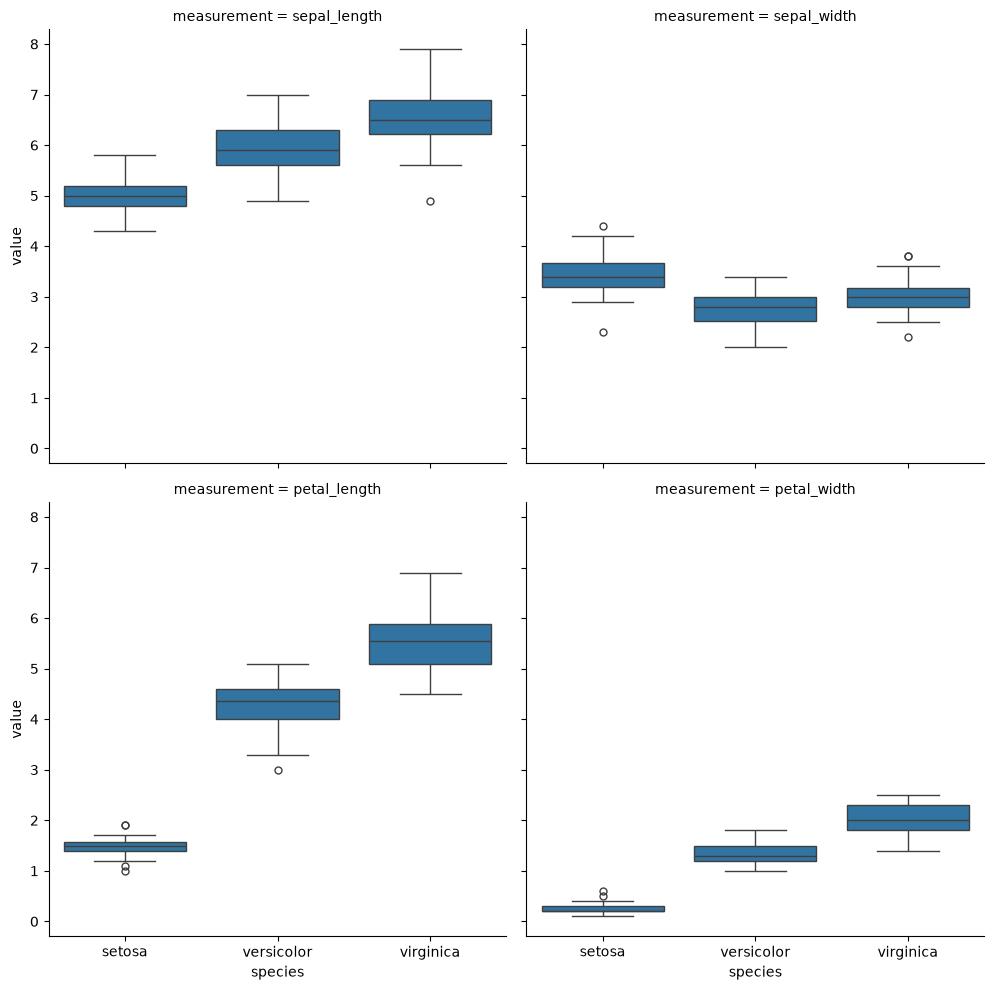

In [19]:
sns.catplot(data=long, x="species", y="value", col="measurement",
            kind="box", col_wrap=2)

<Axes: xlabel='measurement', ylabel='value'>

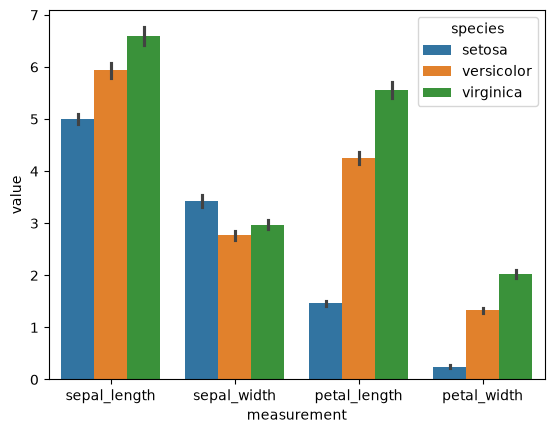

In [21]:
sns.barplot(data=long, x="measurement", y= "value", hue= "species")

5) Reverse exercise 1: reshape the long table back into the original wide format with pivot. Verify it matches the original (column order may differ). Hint: Use ``df.columns.name = None" and df.reset_index() to restore the indices. 

In [26]:
wide = long.pivot(index= ["id", "species"],columns= "measurement", values= "value")
wide

,measurement,petal_length,petal_width,sepal_length,sepal_width
id,species,,,,
0,setosa,1.4,0.2,5.1,3.5
1,setosa,1.4,0.2,4.9,3.0
2,setosa,1.3,0.2,4.7,3.2
3,setosa,1.5,0.2,4.6,3.1
4,setosa,1.4,0.2,5.0,3.6
...,...,...,...,...,...
145,virginica,5.2,2.3,6.7,3.0
146,virginica,5.0,1.9,6.3,2.5
147,virginica,5.2,2.0,6.5,3.0


In [29]:
wide.columns.name=None
wide.reset_index()
wide
# get rid of the column name "measurement" which is not needed anymore

,,petal_length,petal_width,sepal_length,sepal_width
id,species,,,,
0,setosa,1.4,0.2,5.1,3.5
1,setosa,1.4,0.2,4.9,3.0
2,setosa,1.3,0.2,4.7,3.2
3,setosa,1.5,0.2,4.6,3.1
4,setosa,1.4,0.2,5.0,3.6
...,...,...,...,...,...
145,virginica,5.2,2.3,6.7,3.0
146,virginica,5.0,1.9,6.3,2.5
147,virginica,5.2,2.0,6.5,3.0


6) Use `pivot_table()` to calculate some aggregates off the `long` table.

In [30]:
wide= long.pivot_table(index= ["species"], columns= "measurement", values="value", aggfunc="std")
wide

measurement,petal_length,petal_width,sepal_length,sepal_width
species,,,,
setosa,0.173664,0.105386,0.352490,0.379064
versicolor,0.469911,0.197753,0.516171,0.313798
virginica,0.551895,0.274650,0.635880,0.322497
